# 08 · Ethics & Limitations
Module 6.2 (Ethics in Data Science)

A model with good accuracy can still be **unfair, unsafe or misleading**. This notebook looks at the dataset's biases, checks whether
the model works equally well for men and women, and discusses privacy, the role of doctors, and reproducibility.

### Setup
We import the usual libraries plus our own `src/` package. `src` holds all reusable code (statistics formulas, outlier detectors, model pipelines, plot styles) so the notebooks and the Streamlit app use exactly the same logic. The random seed is fixed to **42** so every run gives the same numbers.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so we can use our own src/ package
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src import config as C
from src import data, plots
plots.set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
np.random.seed(C.RANDOM_STATE)
import joblib
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from src import models as M

## 1. Load the data, the saved model and its metrics

In [2]:
df = data.load_raw()
X, y = M.split_xy(df)
pipe = joblib.load(C.MODEL_FILE)
metrics = M.load_json(C.METRICS_FILE)
print("Saved model:", metrics["best_model"])

Saved model: SVM


## 2. Dataset bias
### 2.1 Sex imbalance

In [3]:
sex = df.groupby("Sex").agg(Patients=(C.TARGET, "size"), With_HD=(C.TARGET, "sum"))
sex["% of dataset"] = (sex["Patients"] / len(df) * 100).round(1)
sex["Heart disease rate"] = (sex["With_HD"] / sex["Patients"] * 100).round(1).astype(str) + "%"
sex.index = sex.index.map({"M": "Male", "F": "Female"})
sex

,Patients,With_HD,% of dataset,Heart disease rate
Sex,,,,
Female,193,50,21.000,25.9%
Male,725,458,79.000,63.2%


### 2.2 Where the data comes from
The Kaggle dataset merges five older datasets (source: dataset documentation by fedesoriano):

| Source | Patients |
|---|---|
| Cleveland Clinic (Ohio, USA) | 303 |
| Hungarian Institute of Cardiology (Budapest, Hungary) | 294 |
| University Hospitals Zurich & Basel (Switzerland) | 123 |
| VA Medical Center (Long Beach, California, USA) | 200 |
| Statlog (Heart) dataset (UCI) | 270 |
| **Total before removing duplicates** | **1190** |
| **After removing 272 duplicates** | **918** |

**Why the results may not generalise to Indian patients**
* All patients come from **US and European hospitals**, mostly collected in the **1980s**. No Indian (or South Asian) patients are included.
* South Asians tend to develop coronary artery disease **about 5–10 years earlier**, often at **lower BMI and cholesterol levels**, and have a
  different lipid profile. Cut-offs the model learned (e.g. what counts as "high" cholesterol) may not apply.
* The patients were people **referred to a cardiology clinic** - already suspected of heart problems. 55% have heart disease, far more than in the
  general population, so predicted probabilities would be **too high** if the tool were used for general screening.
* Women are **under-represented (21%)** - see below.
* Before any real use, the model would have to be re-validated on data from Indian hospitals.

## 3. Does the model work equally well for men and women?
We compute **recall** (the share of sick patients that the model catches) separately for male and female patients.
We do it twice:
1. on the **hold-out test set** (the exact split used in notebook 07), and
2. with **10-fold cross-validated predictions** on all 918 patients - more reliable, because the test set has only about 40 women.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=C.RANDOM_STATE)
test_pred = pipe.predict(X_test)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=C.RANDOM_STATE)
oof_pred = cross_val_predict(clone(pipe), X, y, cv=cv)

def by_sex(X_part, y_true, y_pred, label):
    rows = []
    for code, name in [("M", "Male"), ("F", "Female")]:
        mask = (X_part["Sex"] == code).to_numpy()
        m = M.classification_metrics(y_true[mask], y_pred[mask])
        rows.append({"Evaluation": label, "Sex": name, "Patients": int(mask.sum()), "With HD": int(y_true[mask].sum()),
                     "Recall": m["recall"], "Precision": m["precision"], "Specificity": m["specificity"],
                     "Missed (FN)": m["fn"], "False alarms (FP)": m["fp"]})
    return rows

fair = pd.DataFrame(by_sex(X_test, y_test.to_numpy(), test_pred, "Hold-out test set")
                    + by_sex(X, y.to_numpy(), oof_pred, "10-fold CV (all patients)"))
fair.round(3)

,Evaluation,Sex,Patients,With HD,Recall,Precision,Specificity,Missed (FN),False alarms (FP)
0,Hold-out test set,Male,146,96,0.906,0.879,0.760,9,12
1,Hold-out test set,Female,38,6,0.833,0.714,0.938,1,2
2,10-fold CV (all patients),Male,725,458,0.919,0.881,0.787,37,57
3,10-fold CV (all patients),Female,193,50,0.820,0.707,0.881,9,17


The **recall gap** = male recall − female recall. A positive gap means the model misses sick women more often than sick men.

In [5]:
gaps = {}
for label, grp in fair.groupby("Evaluation", sort=False):
    rm = grp.loc[grp.Sex == "Male", "Recall"].item()
    rf = grp.loc[grp.Sex == "Female", "Recall"].item()
    gaps[label] = {"male_recall": rm, "female_recall": rf, "gap": rm - rf}
    print(f"{label:28s} recall male = {rm:.3f}, female = {rf:.3f}  ->  gap (male − female) = {rm - rf:+.3f}")

Hold-out test set            recall male = 0.906, female = 0.833  ->  gap (male − female) = +0.073
10-fold CV (all patients)    recall male = 0.919, female = 0.820  ->  gap (male − female) = +0.099


A bar chart makes the gap easy to see in both evaluations:

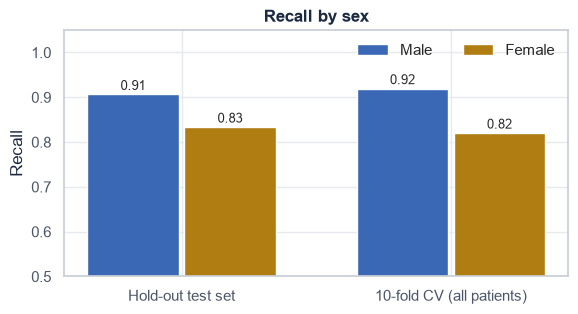

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
labels = list(gaps)
xs = np.arange(len(labels))
ax.bar(xs - 0.18, [gaps[l]["male_recall"] for l in labels], 0.34, color=C.PALETTE_LIGHT[2], label="Male")
ax.bar(xs + 0.18, [gaps[l]["female_recall"] for l in labels], 0.34, color=C.PALETTE_LIGHT[3], label="Female")
for i, l in enumerate(labels):
    ax.text(i - 0.18, gaps[l]["male_recall"] + 0.01, f"{gaps[l]['male_recall']:.2f}", ha="center", fontsize=9)
    ax.text(i + 0.18, gaps[l]["female_recall"] + 0.01, f"{gaps[l]['female_recall']:.2f}", ha="center", fontsize=9)
ax.set_xticks(xs, labels)
ax.set_ylim(0.5, 1.05)
ax.set_ylabel("Recall")
ax.set_title("Recall by sex")
ax.legend(frameon=False, ncol=2, loc="upper right")
plots.save_fig(fig, "08_recall_by_sex")
plt.show()

We store these numbers in the metrics file so the app's *Ethics & About* page can show them.

In [7]:
metrics["fairness"] = {
    "sex_counts": {"Male": int((df.Sex == "M").sum()), "Female": int((df.Sex == "F").sum())},
    "hd_rate": {"Male": float(df.loc[df.Sex == "M", C.TARGET].mean()), "Female": float(df.loc[df.Sex == "F", C.TARGET].mean())},
    "table": fair.to_dict("records"),
    "gaps": gaps,
}
M.save_json(metrics, C.METRICS_FILE)
print("metrics.json updated with fairness results")

metrics.json updated with fairness results

**Why might the model be worse for women?** Only 193 of 918 patients are female and only about 26% of them have heart disease,
so the model sees **very few sick women (≈ 50)** during training. Women also more often show *atypical* symptoms
(e.g. less classic chest pain), which the model learned mostly from men. A gap like this means a deployed tool could
**miss more sick women** - a serious fairness issue that should be fixed (more female data, sex-specific thresholds, or re-weighting) before use.

## 4. Privacy
* Health data is among the **most sensitive personal data**. In India it is protected under the **Digital Personal Data Protection Act, 2023**
  (in Europe by GDPR, in the USA by HIPAA).
* This dataset is **anonymised**: there are no names, IDs, addresses or dates - only clinical measurements. Even so, combinations of age, sex and
  rare values can sometimes re-identify a person, so data should be shared only in aggregated or de-identified form.
* Patients must give **informed consent** for their data to be collected and used for research, and should know how it is stored and who sees it.
* CardioInsight runs **only on the local machine**; the Risk Predictor does not store or send any values a user enters.

## 5. Why this tool must never replace a doctor
* The model gives a **probability based on 11 numbers**; a doctor considers the full history, symptoms, family history, lifestyle,
  medications, imaging and blood tests.
* Even the best model here **misses some sick patients** (false negatives) and **wrongly alarms some healthy ones** (false positives).
* It was trained on a small, old, Western, mostly male, clinic-referred sample (see section 2) and has **never been clinically validated**.
* Medical decisions carry legal and ethical responsibility that only a qualified clinician can take.
* At most it could be a **decision-support** aid that helps prioritise who needs further tests - always with a visible disclaimer, as in the app.

## 6. Reproducibility
A result that cannot be repeated cannot be trusted. This project is reproducible because:
* **Fixed random seeds:** `random_state=42` for every split, CV shuffle, model, bootstrap and permutation (defined once in `src/config.py`).
* **Pinned requirements:** `requirements.txt` lists exact library versions.
* **Notebooks rerun to the same results:** all notebooks run top-to-bottom with `jupyter nbconvert --execute`; the pipeline is saved with `joblib`.
* **Shared code:** all formulas live in `src/`, so the notebooks and the app cannot drift apart.

Check: re-score the saved model on the same test split and compare with the numbers stored by notebook 07.

In [8]:
recomputed = M.classification_metrics(y_test, test_pred)["recall"]
stored = metrics["best"]["holdout_metrics"]["recall"]
print(f"Stored test recall: {stored:.6f} | recomputed now: {recomputed:.6f} | identical: {np.isclose(stored, recomputed)}")
assert np.isclose(stored, recomputed)
print("Library versions used:", metrics["versions"])

Stored test recall: 0.901961 | recomputed now: 0.901961 | identical: True
Library versions used: {'python': '3.13.5', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1', 'pandas': '3.0.6', 'numpy': '2.5.3'}


## Key Findings
* **Sex bias:** only **193 of 918 patients (21%) are female**, and only 50 of them have heart disease (25.9% vs 63.2% for men).
* **Origin bias:** all data comes from US and European hospitals (mostly 1980s, clinic-referred patients); results should **not** be assumed to hold for Indian patients without re-validation.
* **Recall gap:** the SVM catches **91.9% of sick men but only 82.0% of sick women** under 10-fold CV - a **gap of ≈ 10 percentage points**. On the hold-out test set the gap is 7 points (0.906 vs 0.833), but that set contains only 6 sick women, so the CV estimate is more reliable. Women would be missed more often.
* **Privacy:** patient data is highly sensitive; this dataset is anonymised, consent and secure local processing are essential, and the app stores nothing.
* **Not a doctor:** the model misses about 1 in 10 sick patients and was never clinically validated - it can only support, never replace, a clinician.
* **Reproducible:** fixed seed 42, pinned requirements, and the stored test recall was reproduced exactly when the saved model was re-scored.